In [1]:
import numpy as np
inf=float("inf")

import pandas as pd

import matplotlib.pyplot as plt
plt.style.use('ggplot')

import scipy.stats as st

import stablerank.srank as sr
import geometry_objects_2021 as ge

from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

import _pickle as pickle

from ripser import ripser


from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Plane figures
- The input is given by: $\mathcal{I}=\{X_d\}_{0\leq d<4000},\ \ \ \ \mathcal{D}=\{0,1,\ldots,3999\}$.
- The data $\mathcal{D}$ consists of 4000 integers $\mathcal{D}=\{0,1,\ldots,3999\}$. 
- Each integer $d$ in $\mathcal{D}$ is represented by a subset $X_d\subset \mathbb{R}^2$ of 800 points. 

For example:



In [4]:
file = open("Data/plain_figures_data", "rb")
plain_figures_data = pickle.load(file)

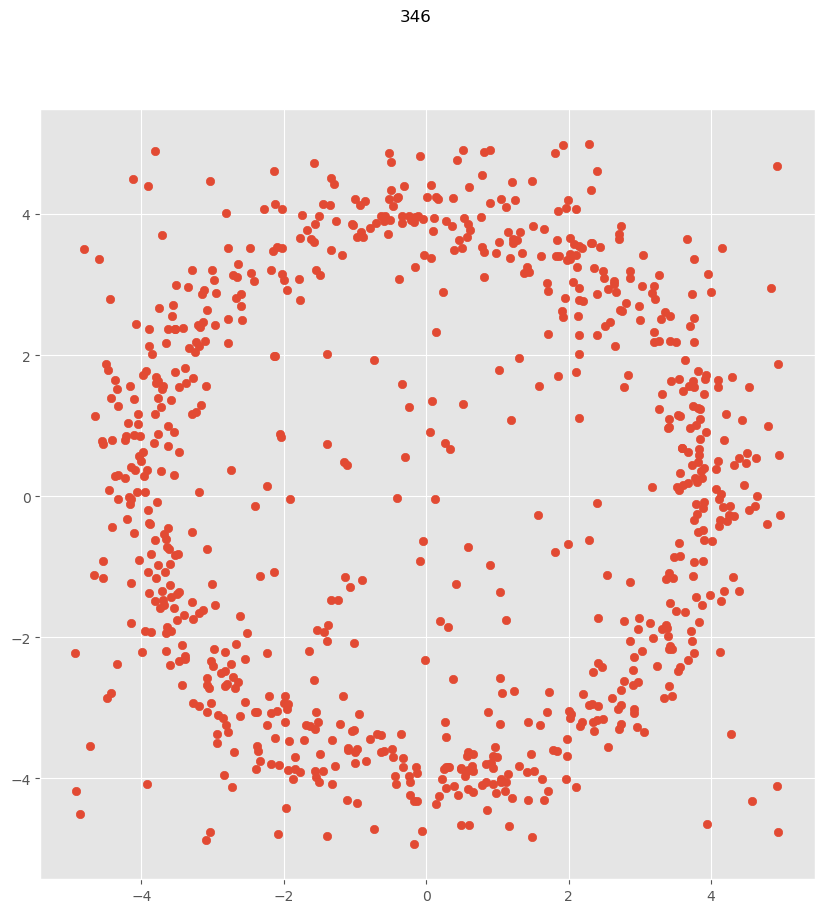

In [6]:
d = 346

fig=plt.figure(figsize=(10, 10))
fig.suptitle(str(d))
figure = plain_figures_data.at[d,"figure"]
plt.scatter(figure[:,0], figure[:,1])

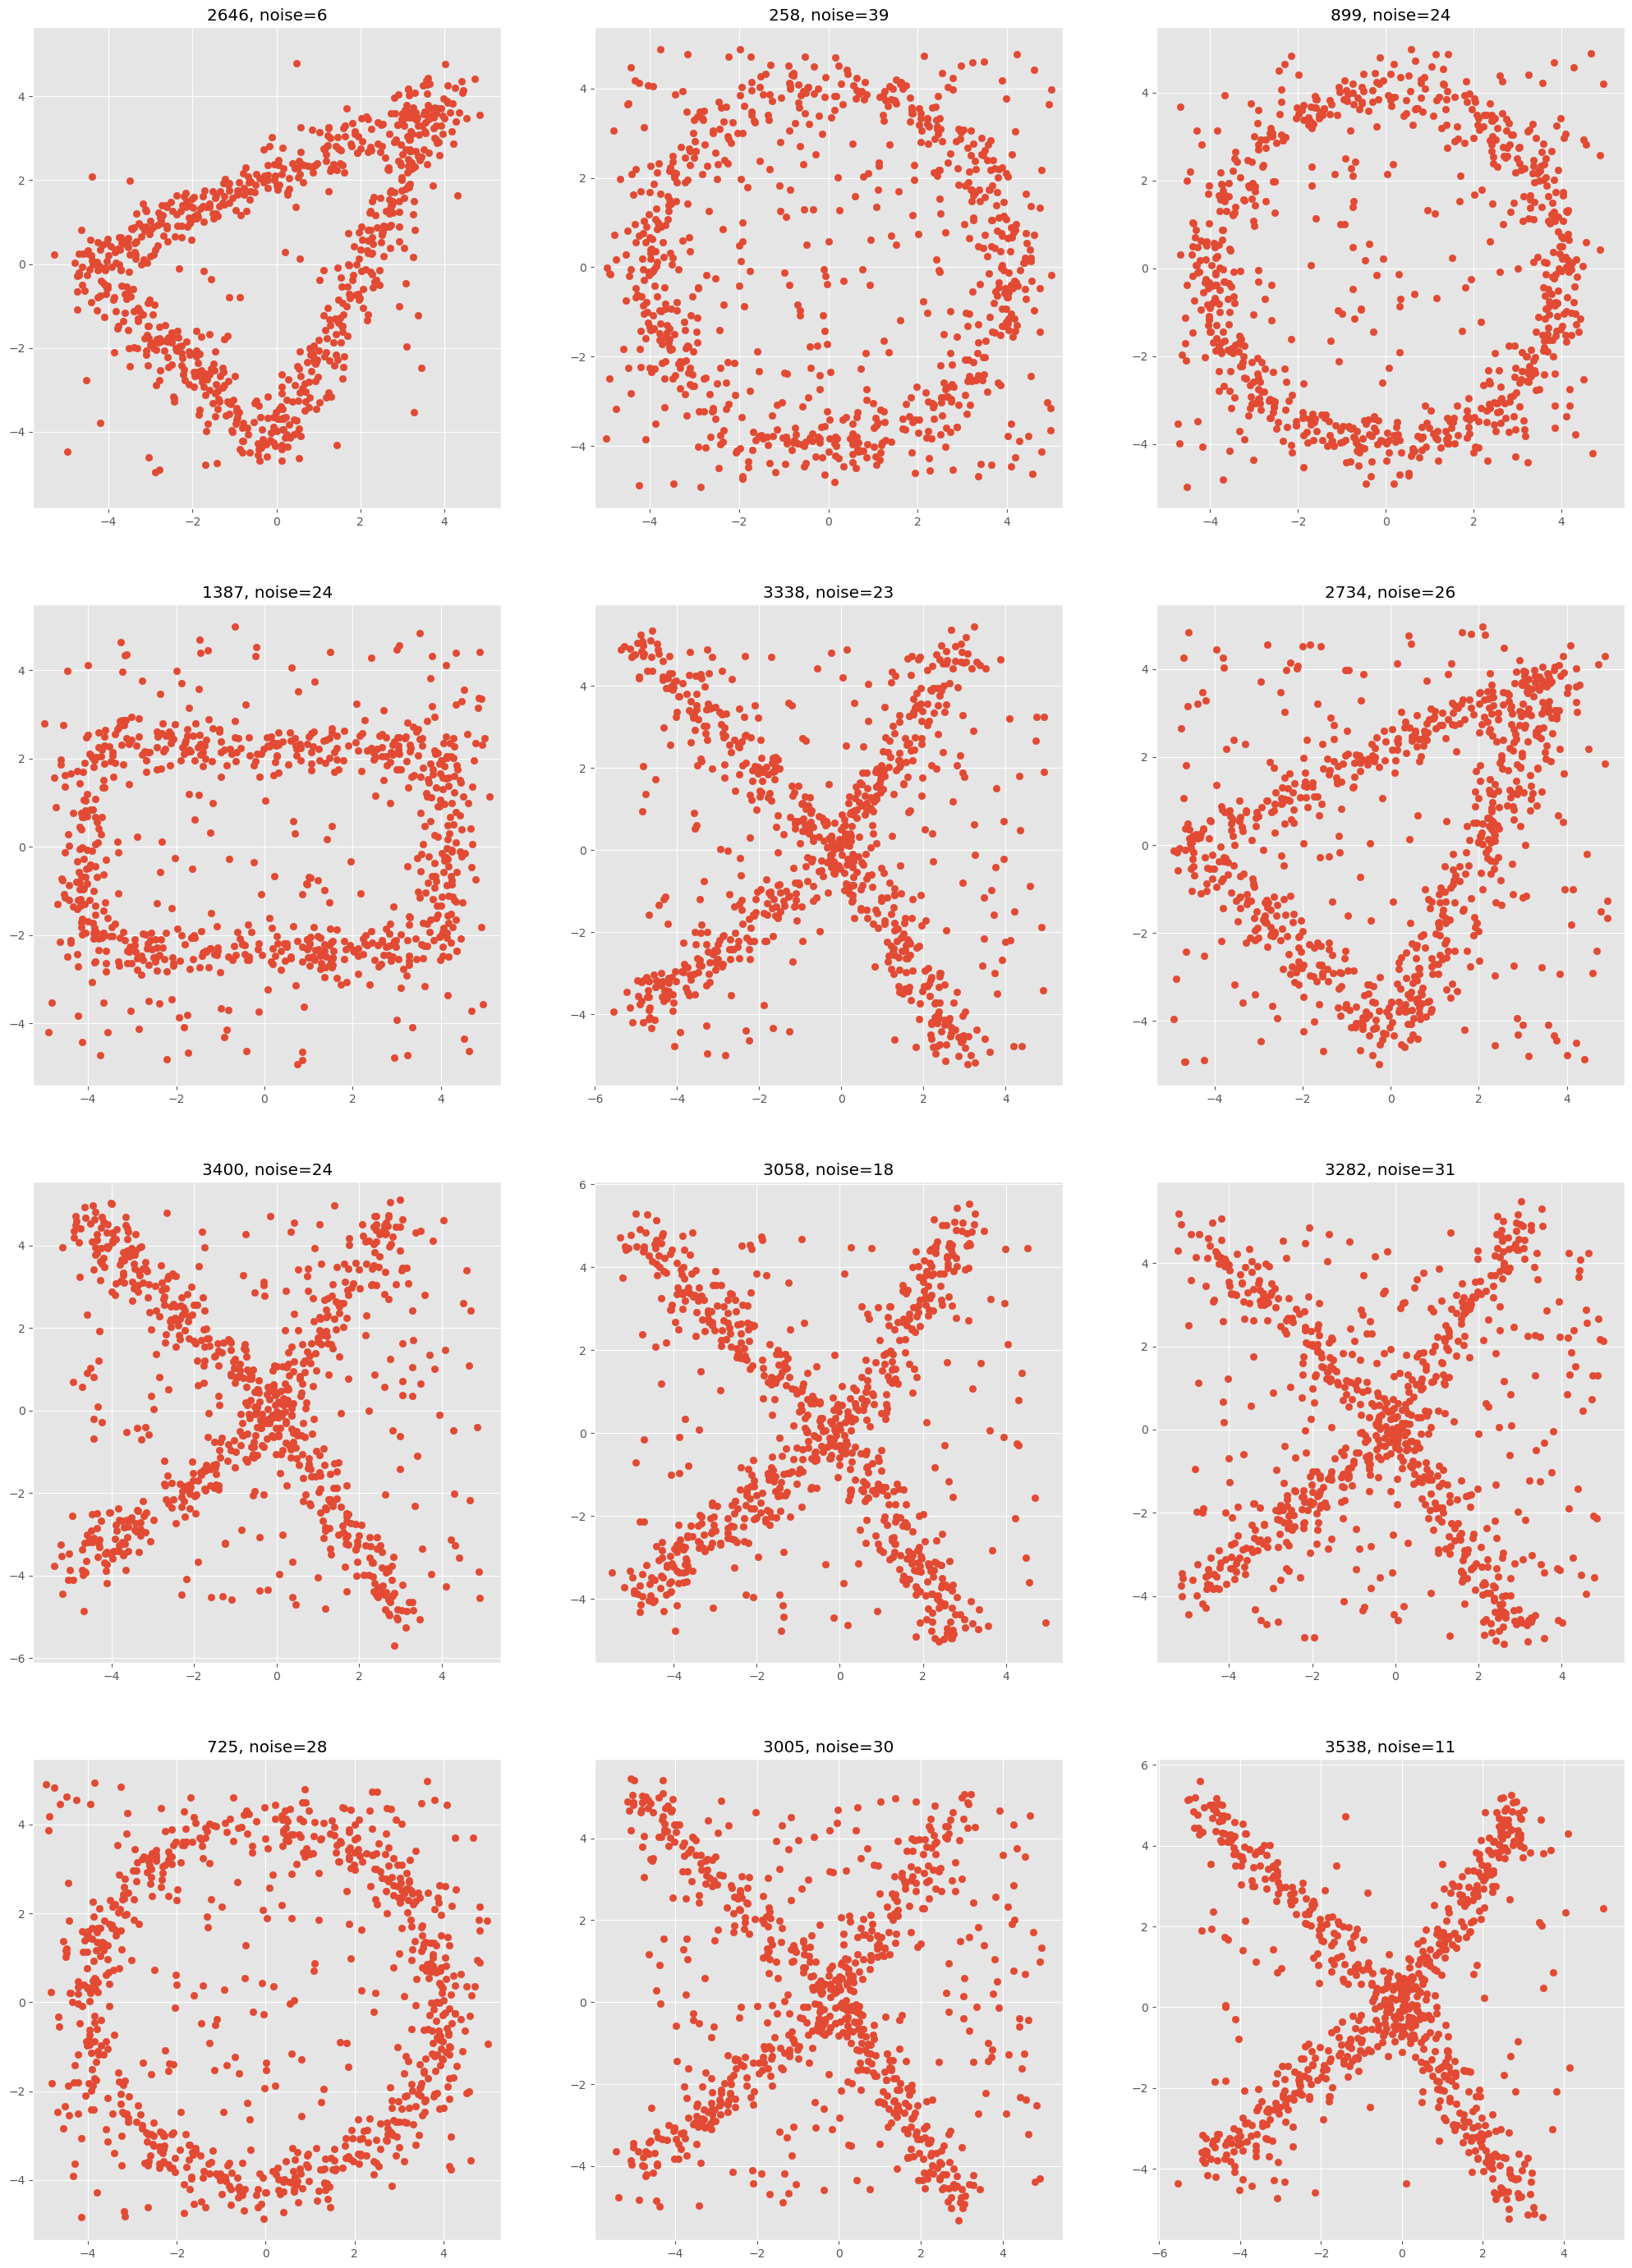

In [8]:
some_data = np.random.choice(4000, 12, replace=False)

plt.figure(figsize=(25, 35))
i=1
for d in some_data:
    ax = plt.subplot(4,3,i)
    bkg_noise = plain_figures_data.at[d,"bkg noise"]
    ax.set_title(str(d)+", "+"noise="+str(bkg_noise))
    plt.axis('equal')
    figure = plain_figures_data.at[d,"figure"]
    plt.scatter(figure[:,0], figure[:,1])
    i=i+1

# Point processes

- The input is given by: $\mathcal{I}=\{X_d\}_{0\leq d<6000},\ \ \ \ \mathcal{D}=\{0,1,\ldots,5999\}$.
- The data $\mathcal{D}$ consists of 6000 integers $\mathcal{D}=\{0,1,\ldots,5999\}$. 
- Each integer $d$ in $\mathcal{D}$ is represented by a subset $X_d\subset \mathbb{R}^2$ of around 200 points. 

For example:

In [11]:
file = open("Data/point_processes_data", "rb")
point_processes_data = pickle.load(file)

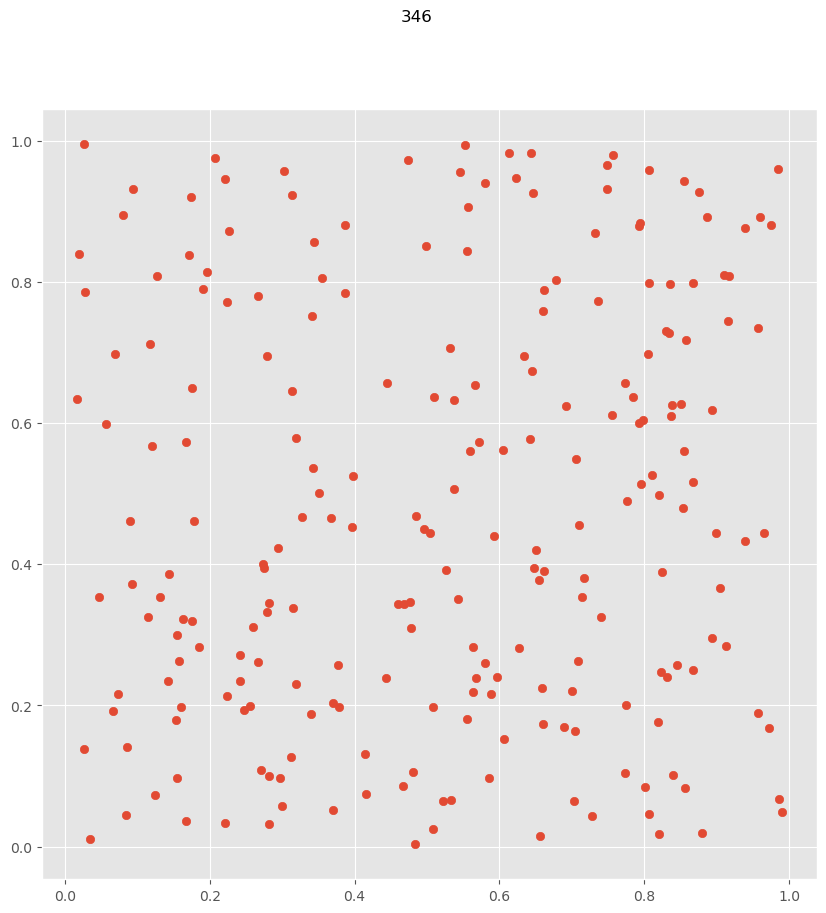

In [13]:
d = 346

fig=plt.figure(figsize=(10, 10))
fig.suptitle(str(d))
figure = point_processes_data.at[d,"figure"]
plt.scatter(figure[:,0], figure[:,1])

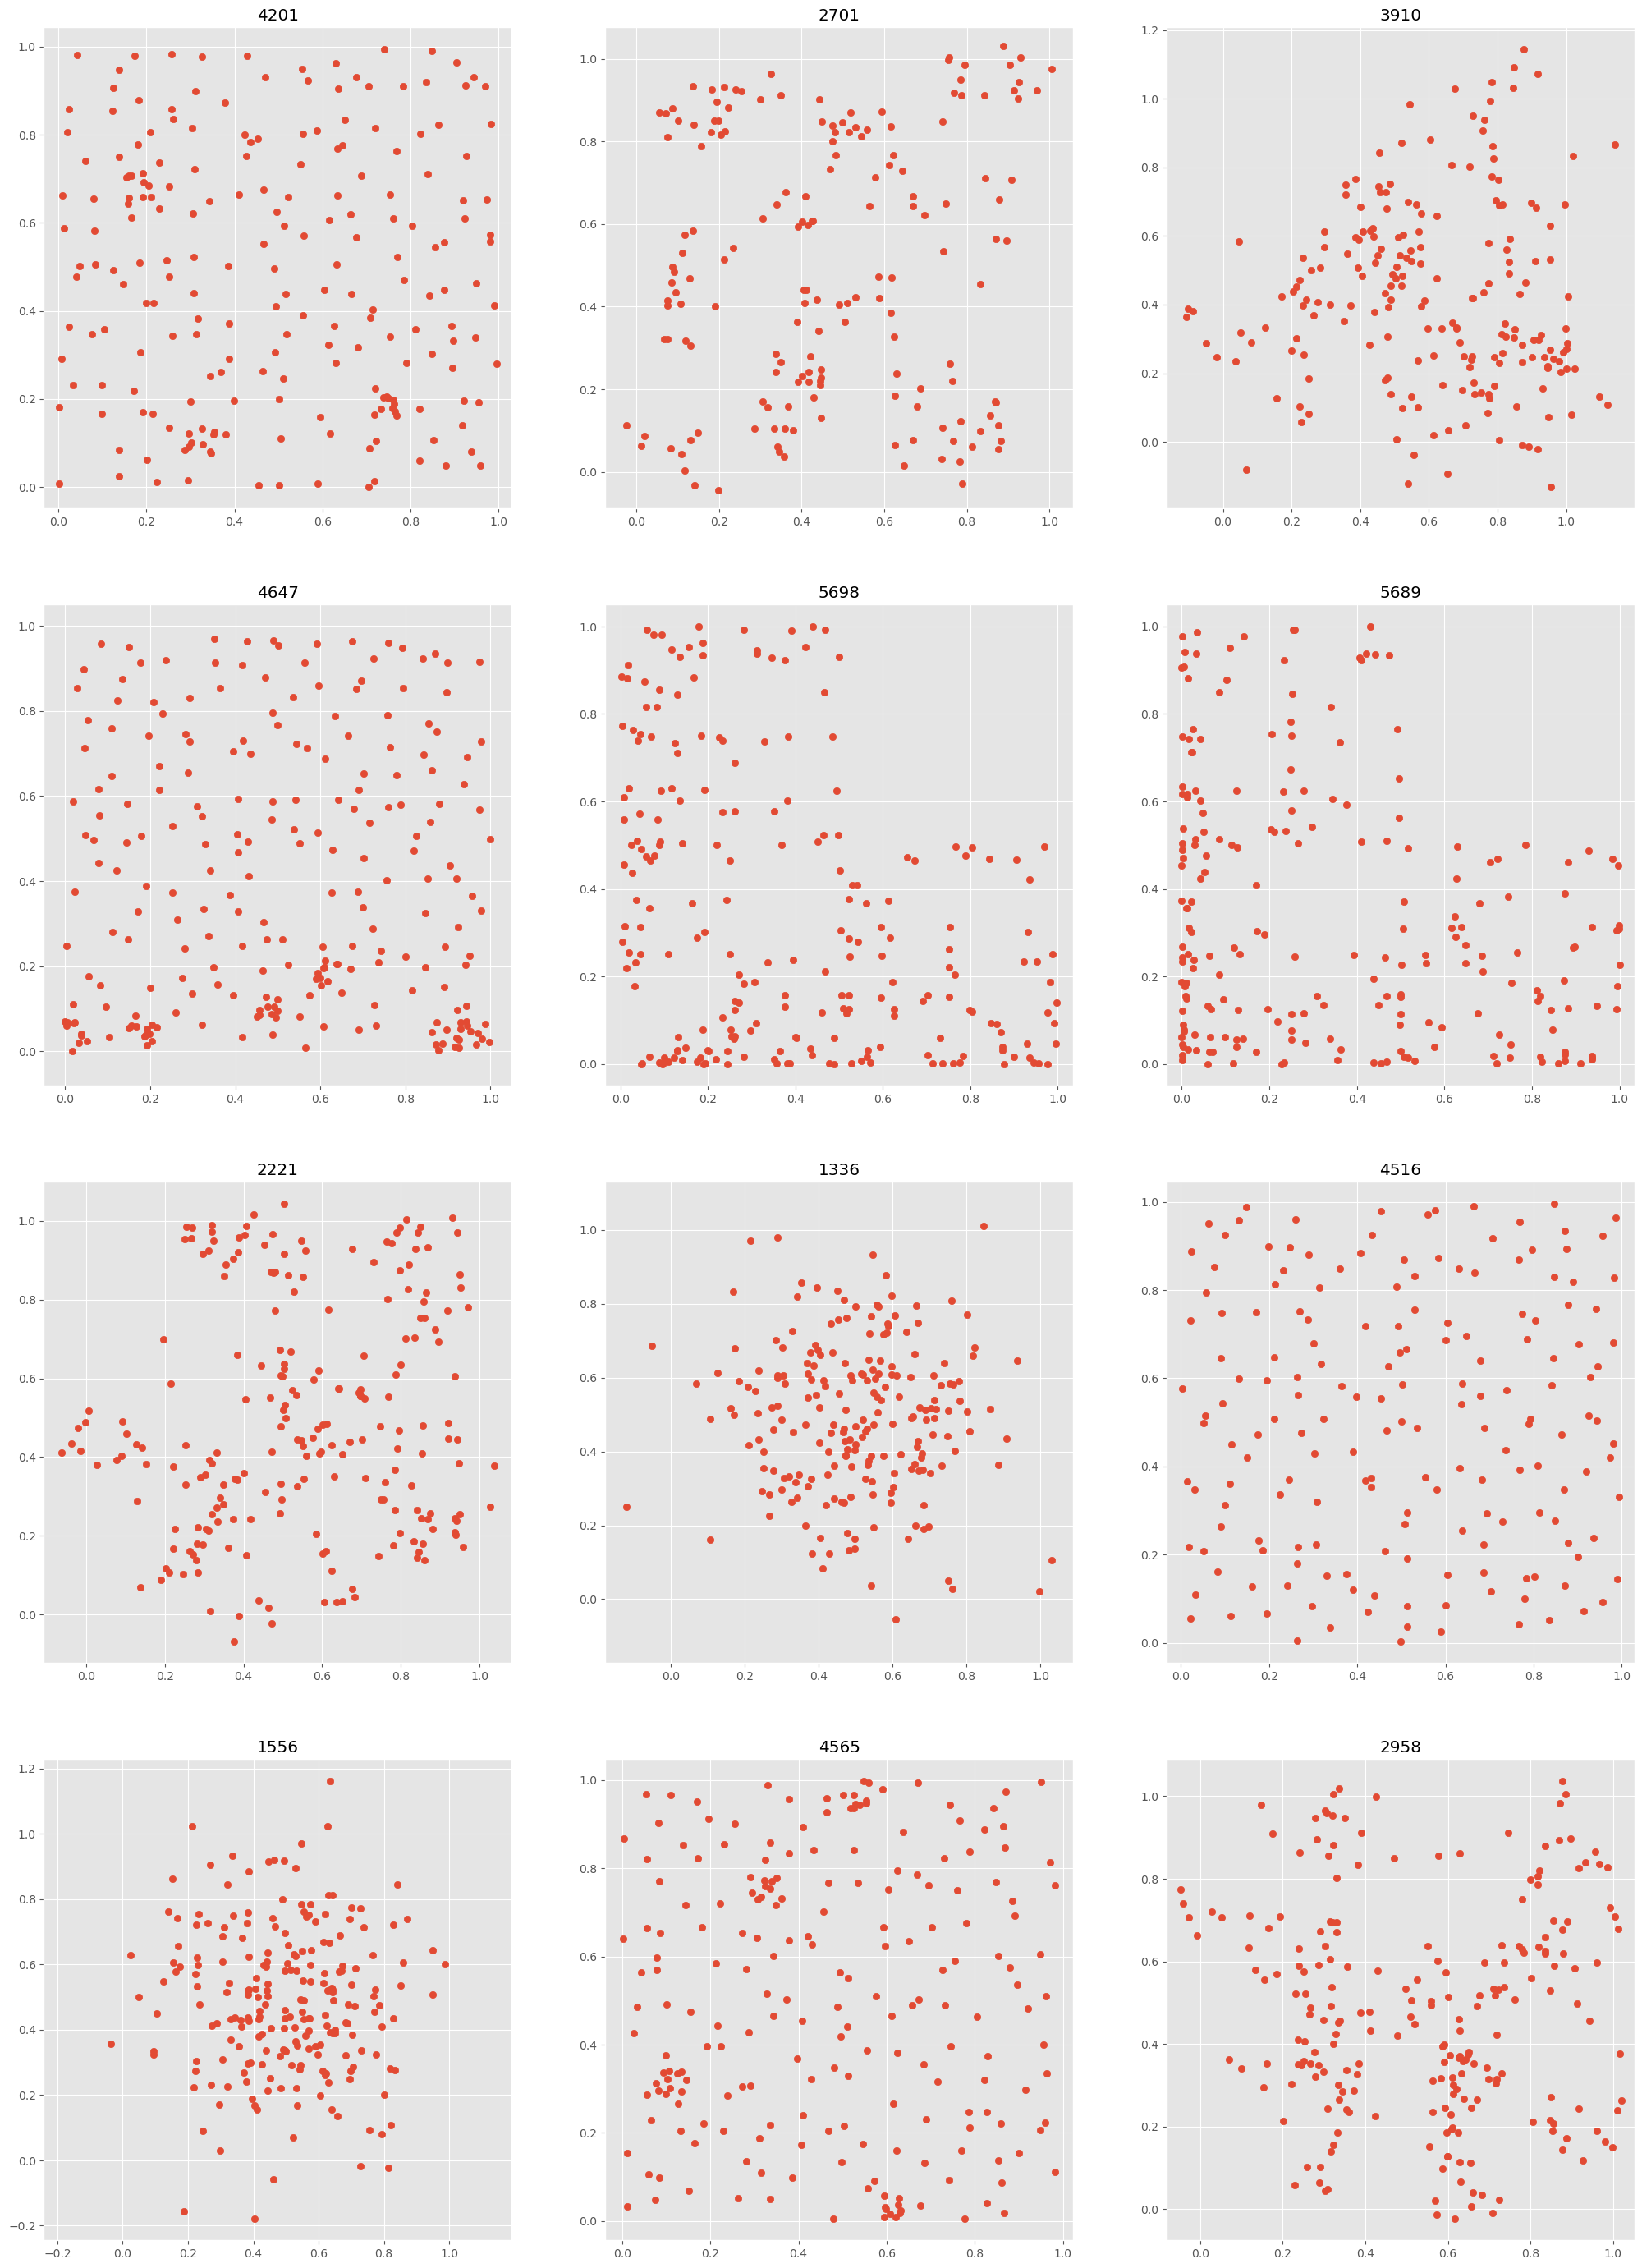

In [15]:
some_data = np.random.choice(6000, 12, replace=False)

plt.figure(figsize=(25, 35))
i=1
for d in some_data:
    ax = plt.subplot(4,3,i)
    ax.set_title(str(d))
    plt.axis('equal')
    figure =point_processes_data.at[d,"figure"]
    plt.scatter(figure[:,0], figure[:,1])
    i=i+1

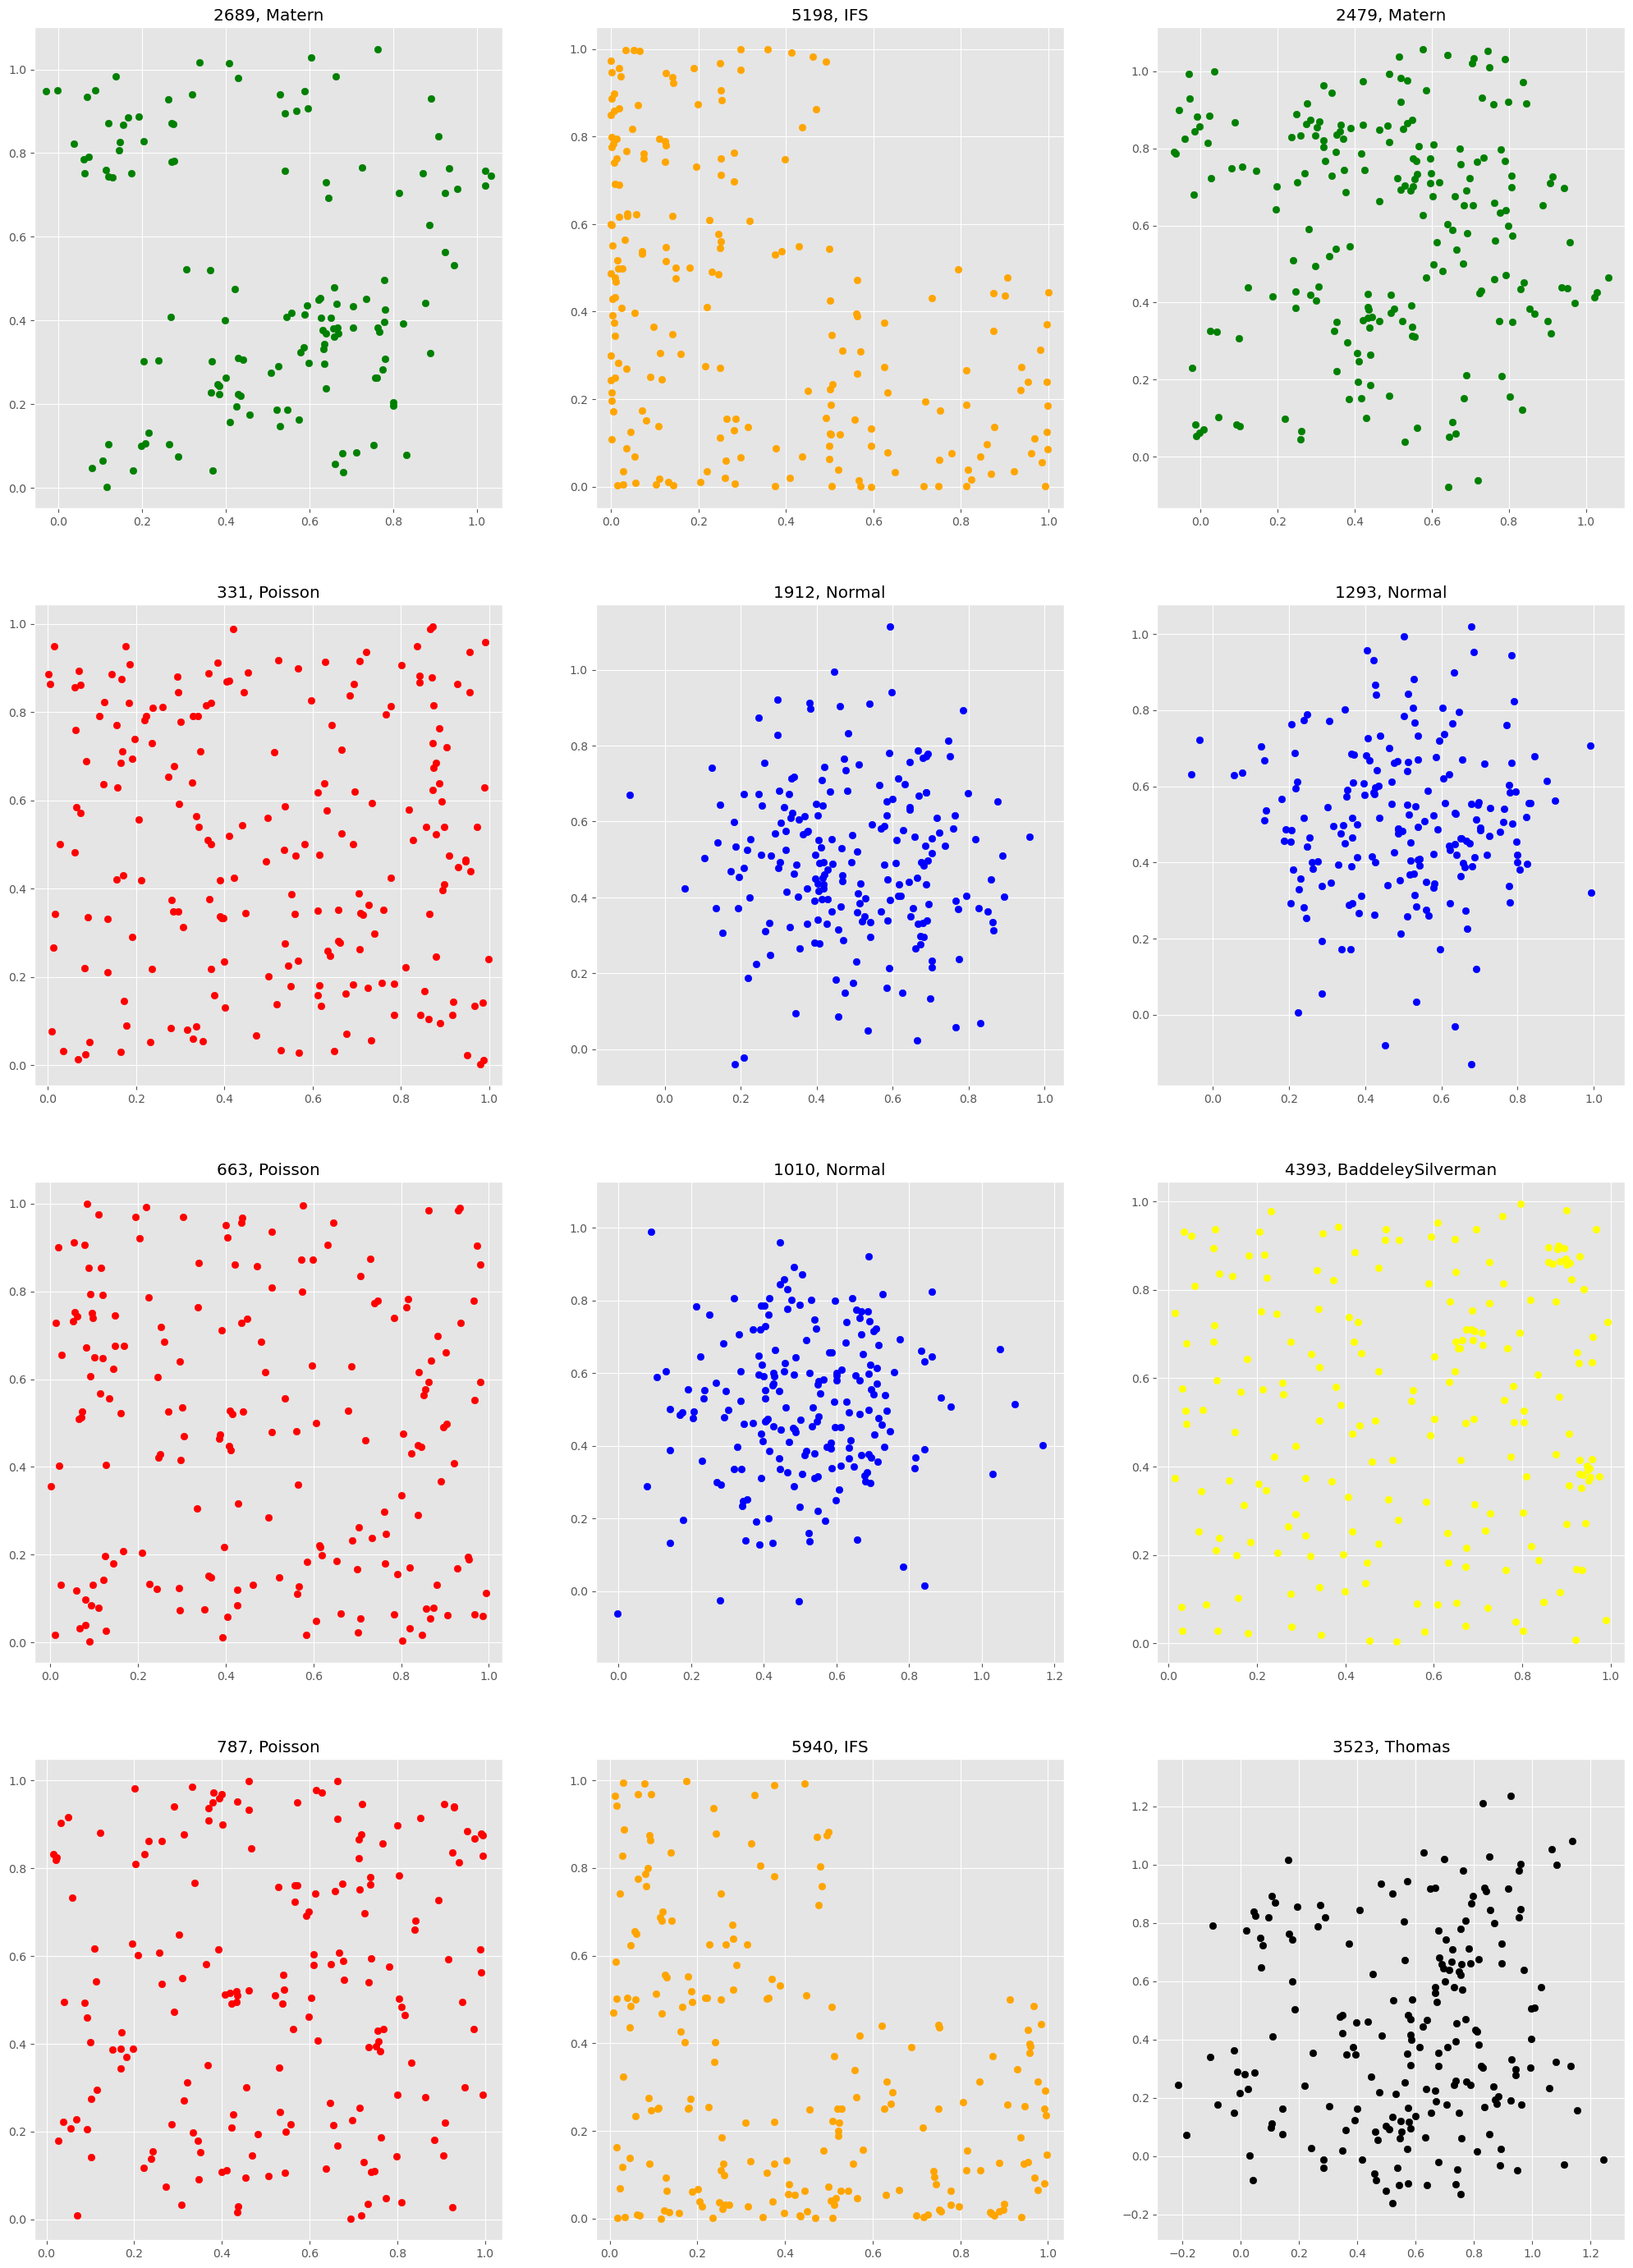

In [19]:
some_data = np.random.choice(6000, 12, replace=False)

plt.figure(figsize=(25, 35))
i=1
for d in some_data:
    distribution = point_processes_data.at[d,"distribution"]
    color =  point_processes_data.at[d,"color"]
    ax = plt.subplot(4,3,i)
    ax.set_title(str(d)+", "+distribution)
    plt.axis('equal')
    figure =point_processes_data.at[d,"figure"]
    plt.scatter(figure[:,0], figure[:,1],color = color)
    #sr.EucObject(figure).plot(color = color)
    i=i+1

# In or out

- The data $\mathcal{D}$ is given by 250 points in the plane $\mathbb{R}^2$:

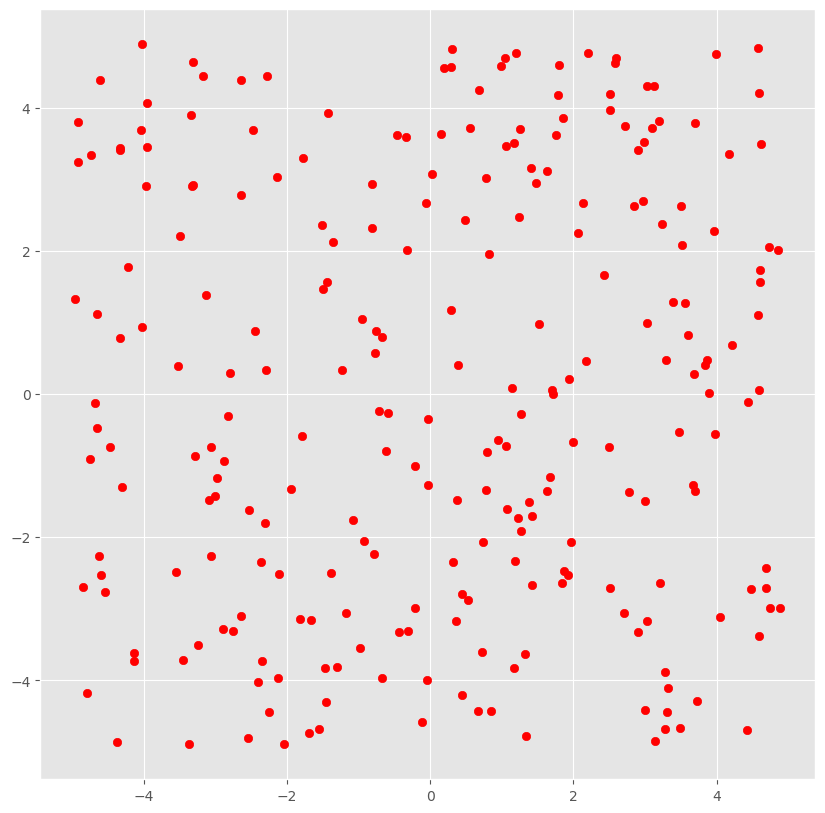

In [22]:
file = open("Data/in_out_index", "rb")
in_out_index = pickle.load(file)

plt.figure(figsize=(10,10))
for p in in_out_index:
    plt.scatter(*p, color = "red")

- The input is given by: $\mathcal{I}=\{X_d\}_{d\in \mathcal{D}}$.
- Every element $d$ in $\mathcal{D}$ is represented by a set $X_d =\{S_0,\ldots, S_{69}\}$ of size $70$
whose elements are called instances.
- Every element $S_i$ in $X_d$ is a subset of $\mathbb{R}^2$ of size 10.

For example:

In [27]:
file = open("Data/in_out_data", "rb")
in_out_data = pd.read_pickle(file)

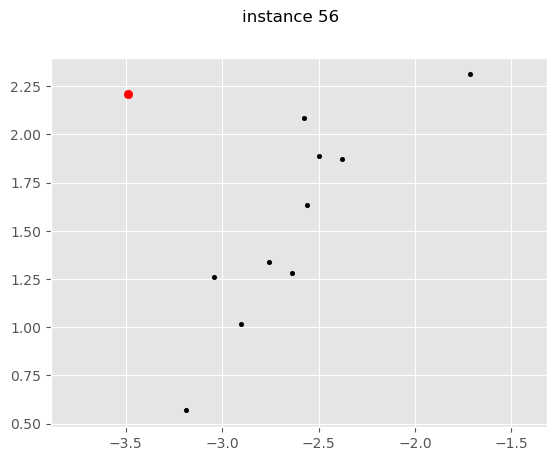

In [29]:
d = in_out_index[13]
inst = 56
fig=plt.figure()
plt.axis('equal')
fig.suptitle("instance "+str(inst))
figure = in_out_data.at[d,inst]
plt.scatter(figure[:,0], figure[:,1],s=10,color = "black")
plt.scatter(*d, c = "red")

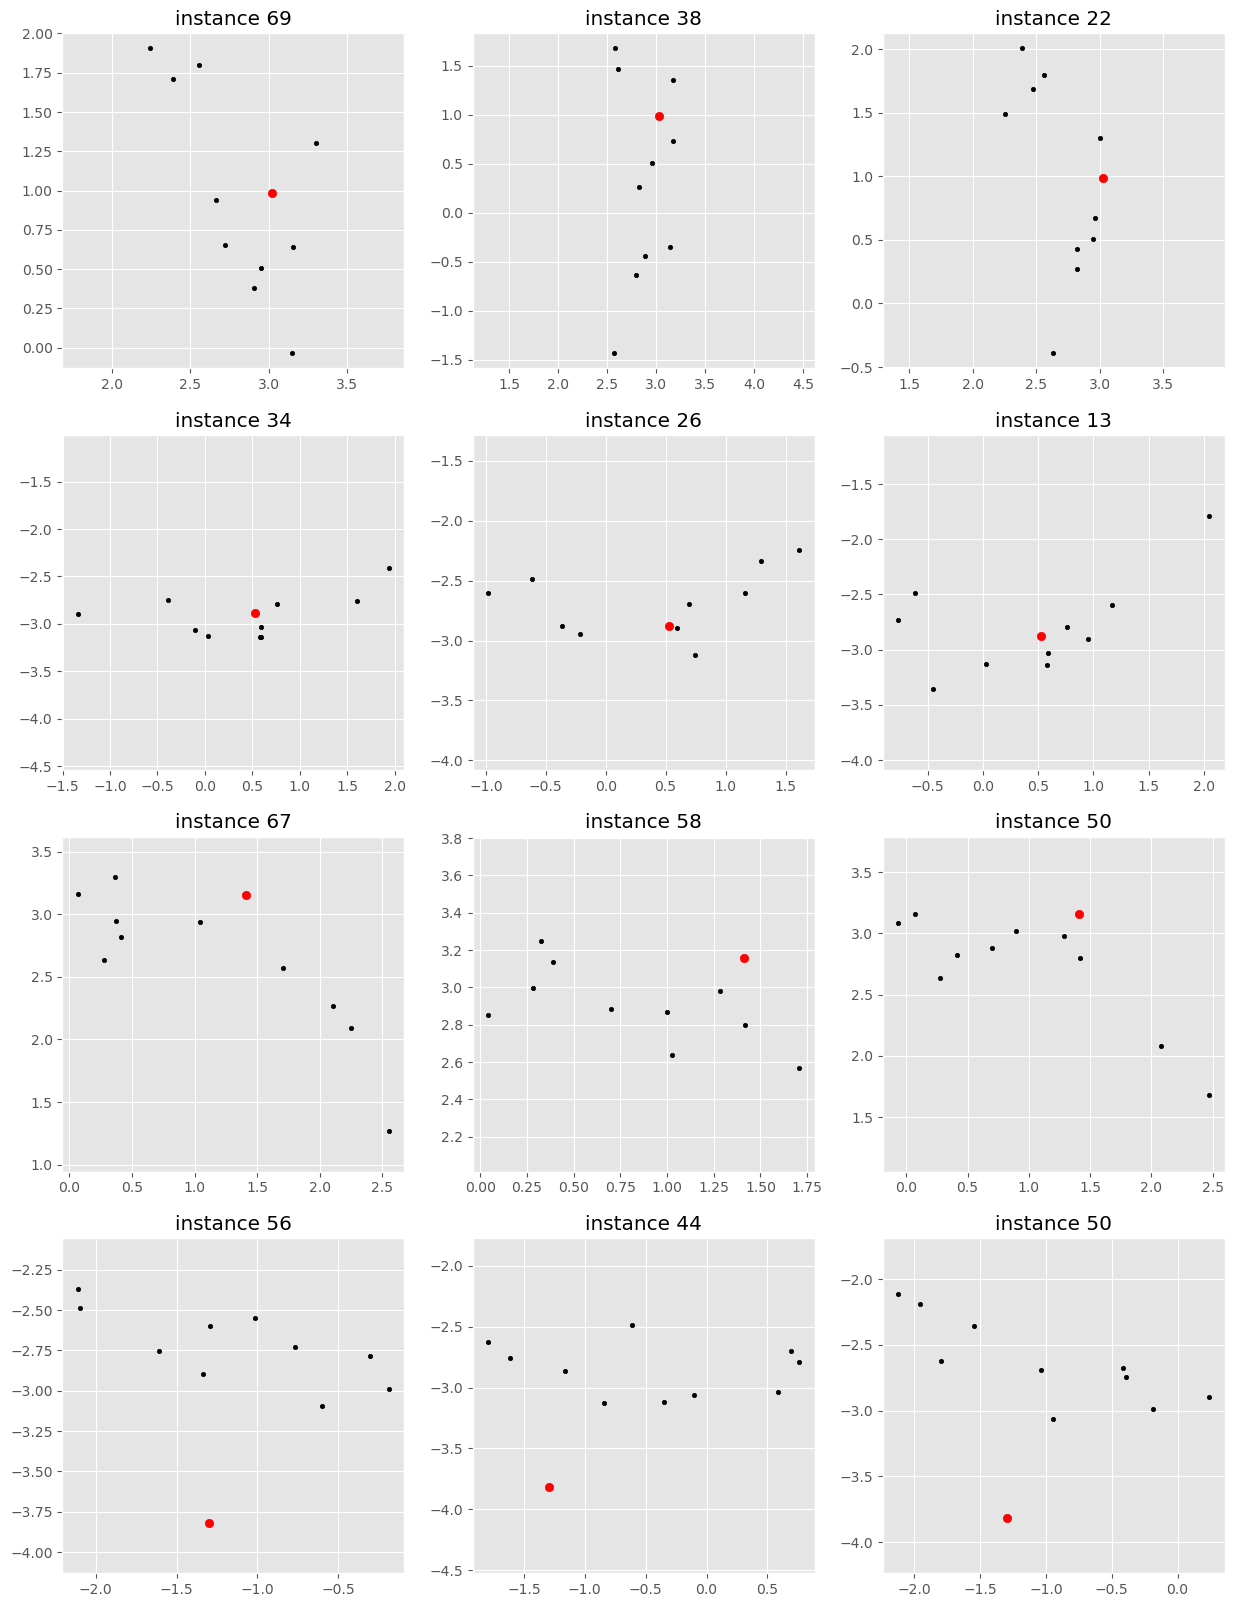

In [31]:
some_points = np.random.choice(250, 4, replace=False)
plt.figure(figsize=(15, 20))
i=1
for p in some_points:
    some_inst = np.random.choice(70,3, replace=False)
    for inst in some_inst:
        point = in_out_index[p]
        ax = plt.subplot(4,3,i)
        plt.axis('equal')
        ax.set_title("instance "+str(inst))
        figure = in_out_data.at[point,inst]
        plt.scatter(figure[:,0], figure[:,1],s=10,color = "black")
        plt.scatter(*point, c = "red")
        i = i+1       

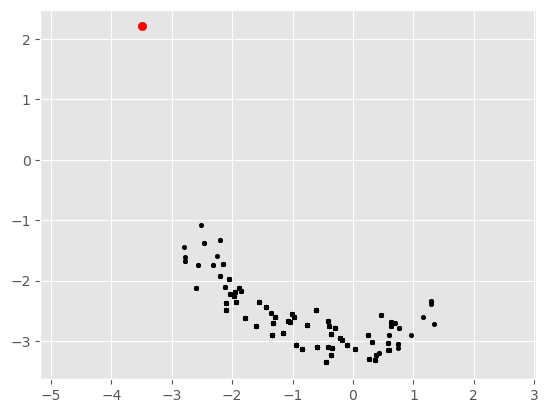

In [33]:
fig=plt.figure()
plt.axis('equal')
plt.scatter(d[0],d[1], c = "red")
d = in_out_index[13]
inst = 0
while inst < 70:
    figure = in_out_data.at[point,inst]
    plt.scatter(figure[:,0], figure[:,1],s=10,color = "black")
    inst = inst+1

In [35]:
file = open("Data/in_out_ref", "rb")
in_out_ref = pd.read_pickle(file)

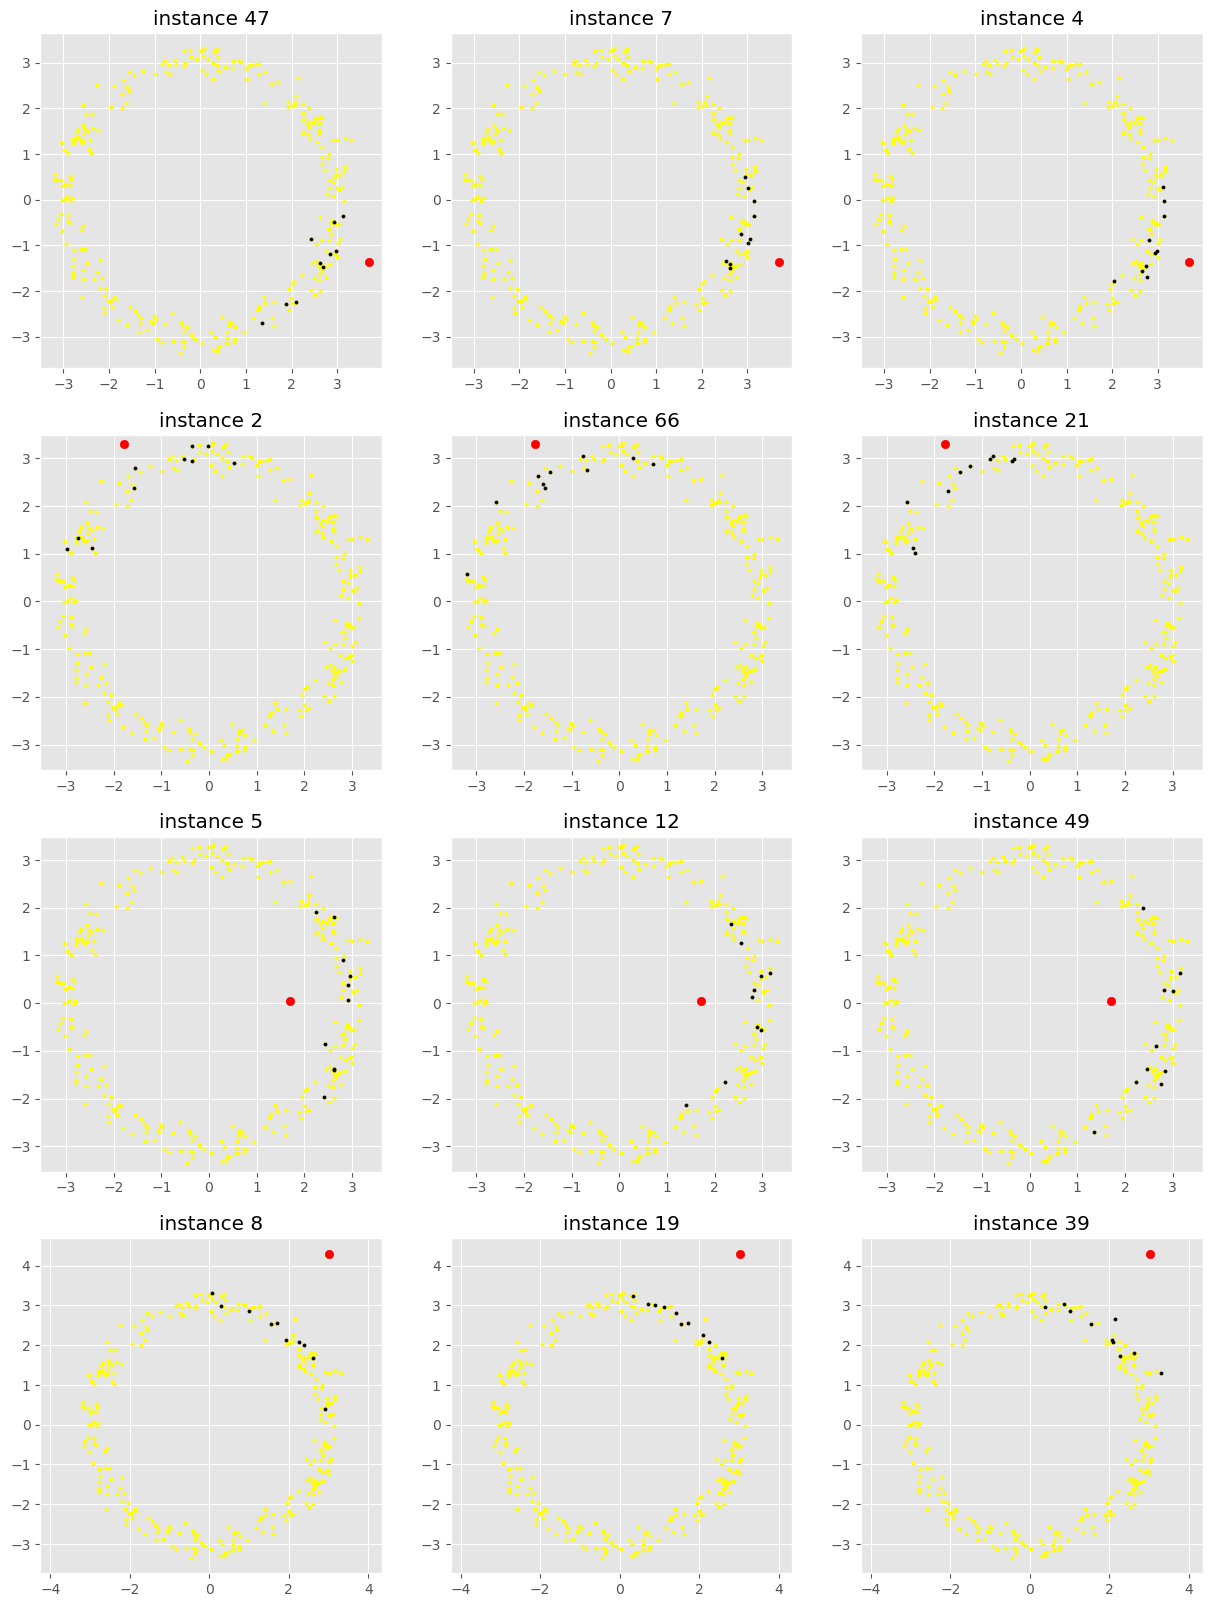

In [37]:
some_points = np.random.choice(250, 4, replace=False)
plt.figure(figsize=(15, 20))
i=1
for p in some_points:
    some_inst = np.random.choice(70,3, replace=False)
    for inst in some_inst:
        point = in_out_index[p]
        ax = plt.subplot(4,3,i)
        plt.axis('equal')
        ax.set_title("instance "+str(inst))
        figure = in_out_data.at[point,inst]
        plt.scatter(in_out_ref [:,0], in_out_ref [:,1],s=5,color = "yellow")
        plt.scatter(figure[:,0], figure[:,1],s=5,color = "black")
        
        plt.scatter(point[0],point[1], c = "red")
        i = i+1       

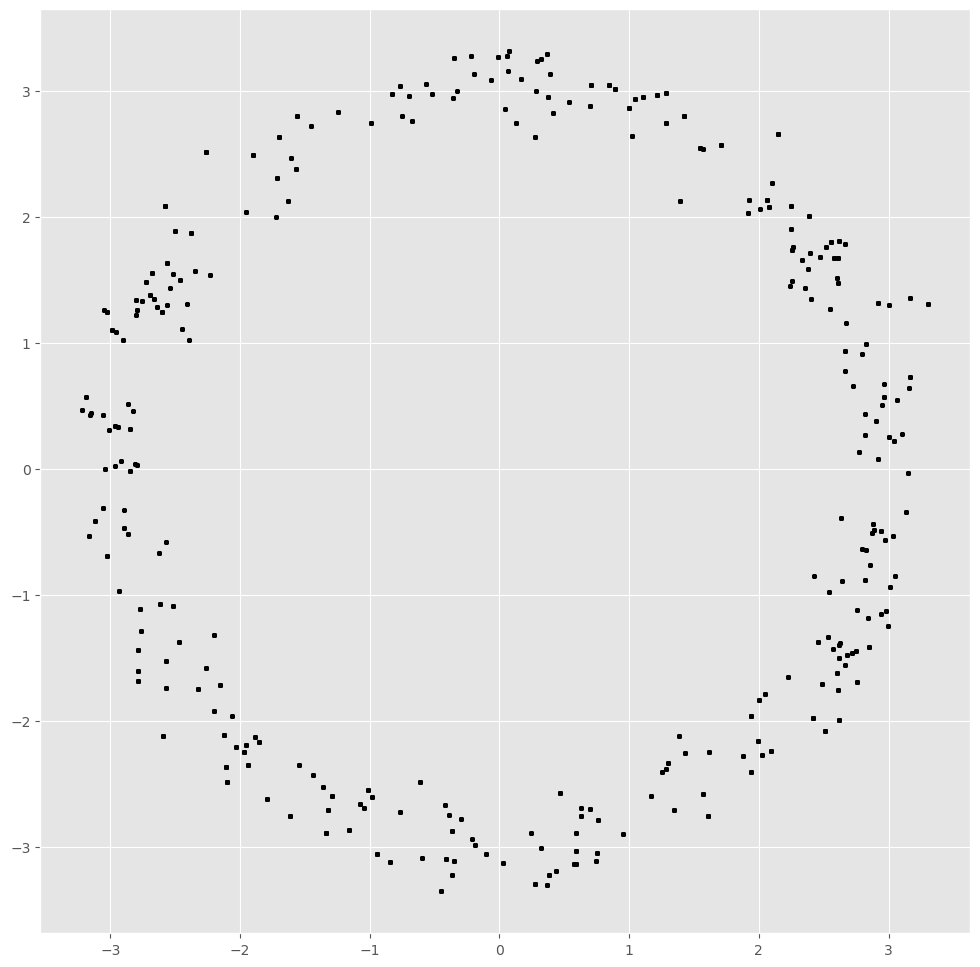

In [39]:
plt.figure(figsize=(12, 12))
for point in in_out_data.index:
    inst = np.random.choice(70, 3, replace=False)
    #plt.scatter(point[0],point[1], c = "red")
    for i in inst:
        figure= in_out_data.at[point,i]
        plt.scatter(figure[:,0], figure[:,1],s=8,color = "black")
        

- The input is given by: $\mathcal{I}=\{X_d\}_{d\in \mathcal{D}}$.
- Every element $d$ in $\mathcal{D}$ is represented by a set $X_d =\{S_0,\ldots, S_{69}\}$ of size $70$
whose elements are called instances.
- Every element $S_i$ in $X_d$ is a subset of $\mathbb{R}^2$ of size 10.
- $S_i$ is constructed in two seteps:
    - first create a subset as before
    - translate this subset by a random vector. 

For example:

In [45]:
file = open("Data/in_out_mod_data", "rb")
in_out_mod_data = pd.read_pickle(file)

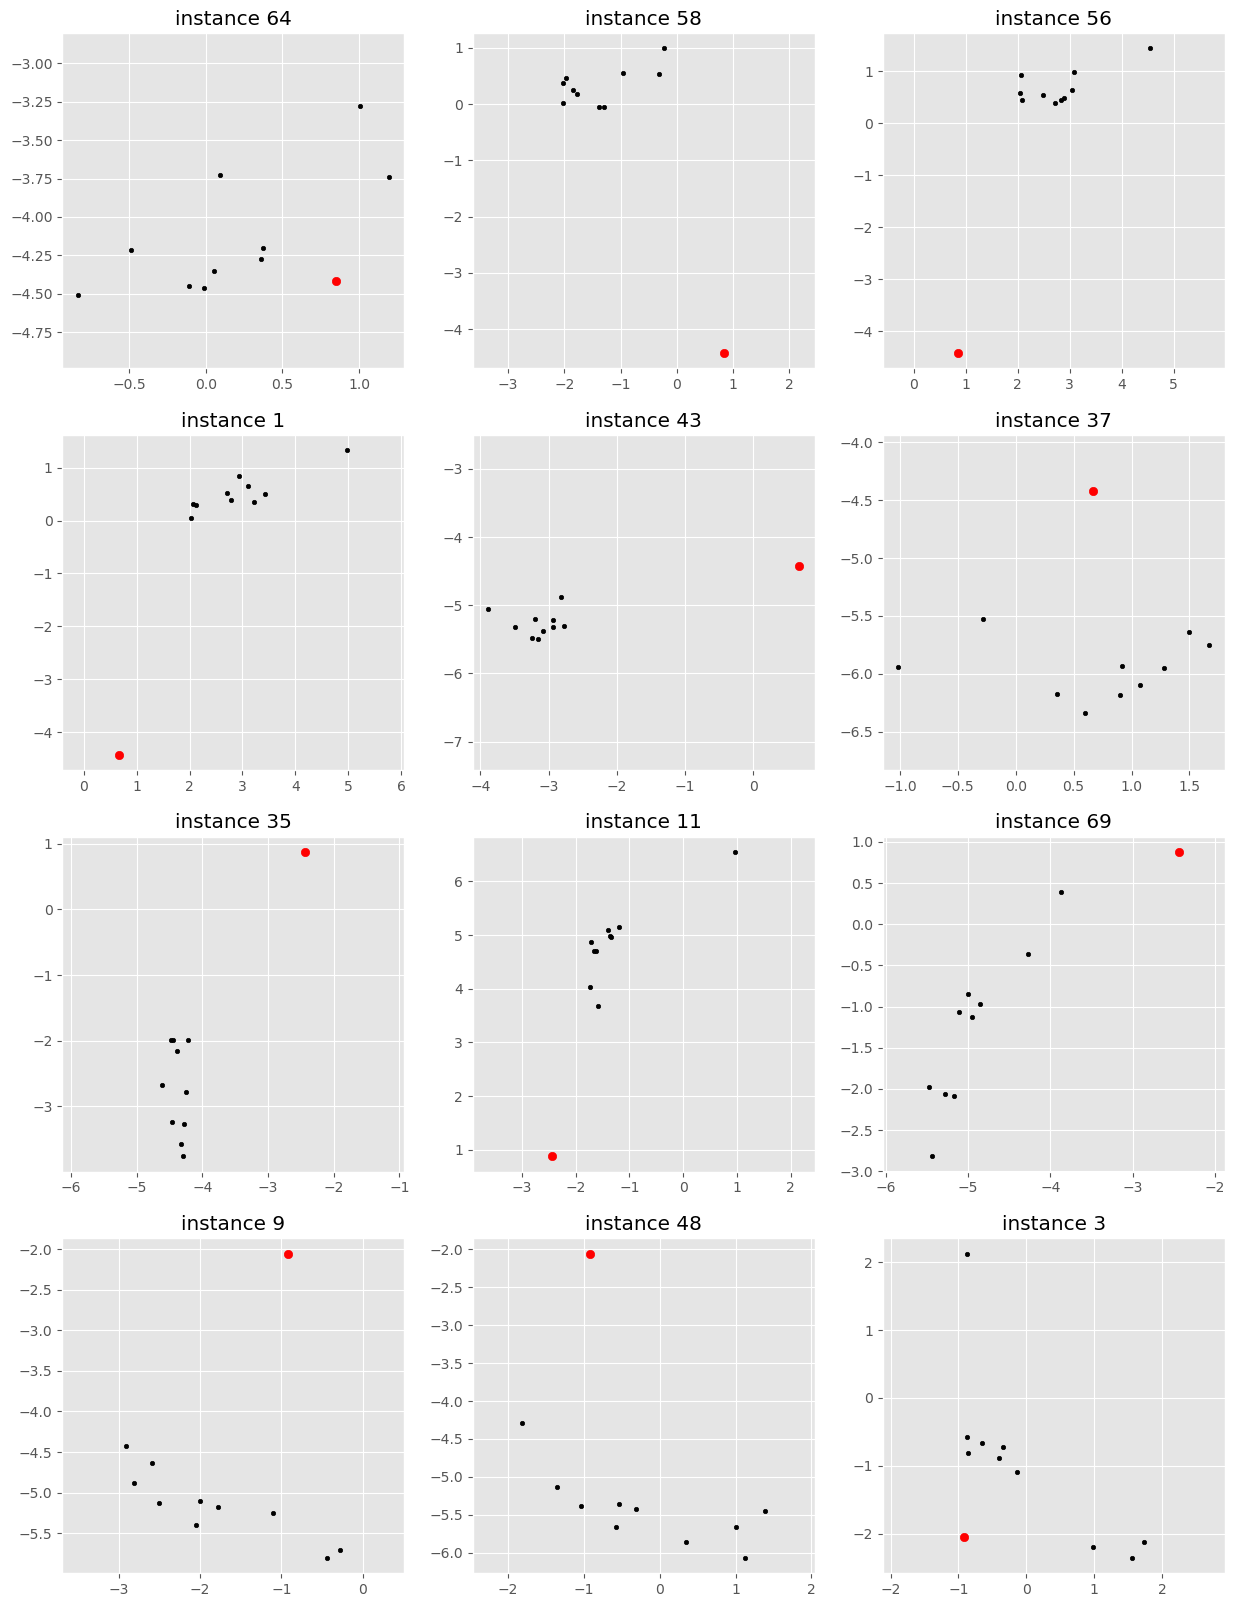

In [47]:
some_points = np.random.choice(250, 4, replace=False)
plt.figure(figsize=(15, 20))
i=1
for p in some_points:
    some_inst = np.random.choice(70,3, replace=False)
    for inst in some_inst:
        point = in_out_index[p]
        ax = plt.subplot(4,3,i)
        plt.axis('equal')
        ax.set_title("instance "+str(inst))
        figure = in_out_mod_data.at[point,inst]
        plt.scatter(figure[:,0], figure[:,1],s=10,color = "black")
        plt.scatter(*point, c = "red")
        i = i+1       

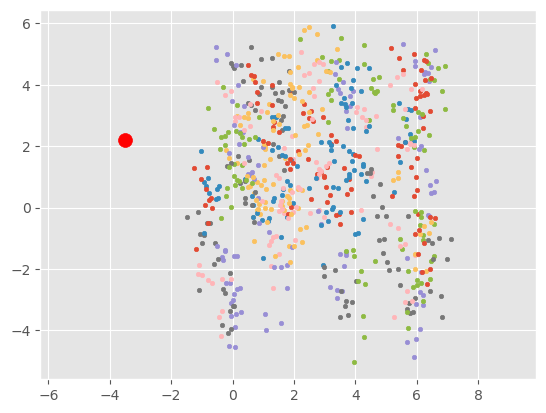

In [49]:
fig=plt.figure()
plt.axis('equal')
plt.scatter(d[0],d[1],s = 100, c = "red")
d = in_out_index[157]
inst = 0
while inst < 70:
    figure = in_out_mod_data.at[d,inst]
    plt.scatter(figure[:,0], figure[:,1],s=10)
    inst = inst+1

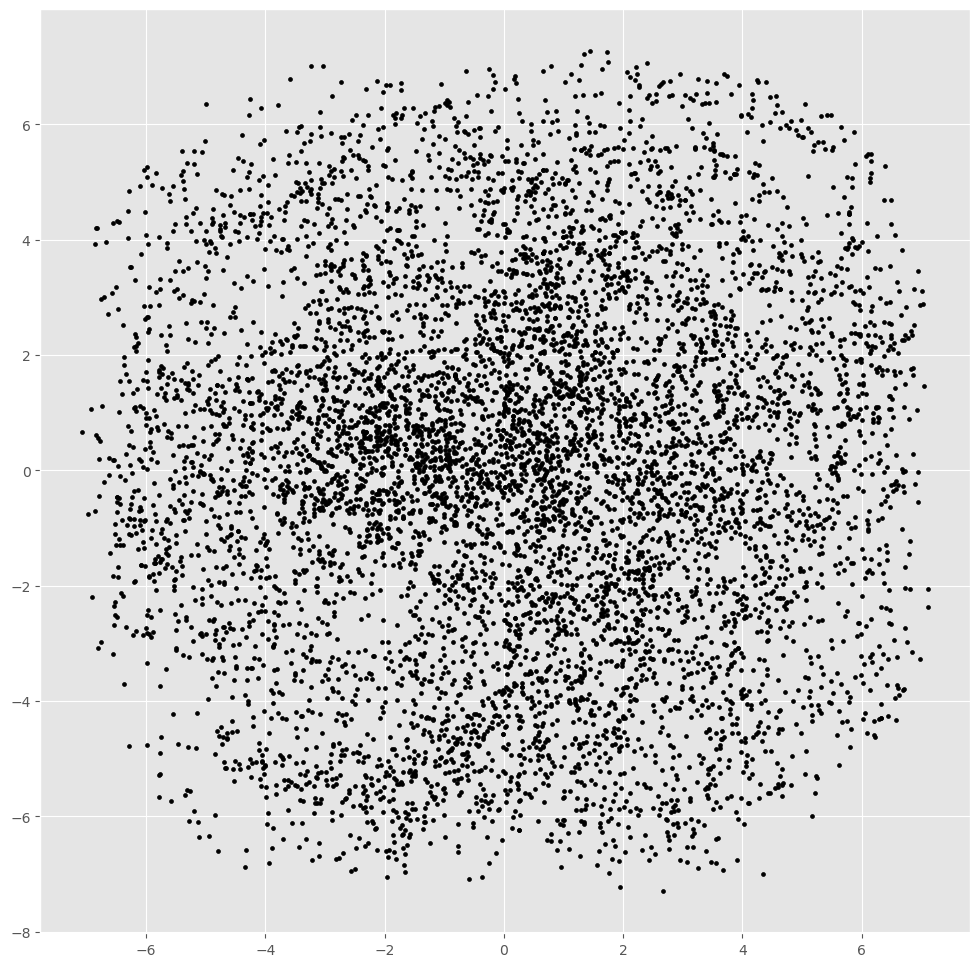

In [51]:
plt.figure(figsize=(12, 12))
for point in in_out_mod_data.index:
    inst = np.random.choice(70, 3, replace=False)
    #plt.scatter(point[0],point[1], c = "red")
    for i in inst:
        figure= in_out_mod_data.at[point,i]
        plt.scatter(figure[:,0], figure[:,1],s=8, color="black")